# 06 · Distance without limits, logicals as strings, and how a code is written

**What this notebook is for.** It goes with explorer update 1. Three questions:
1. *Why was there a cap on the distance?* Our brute force tries every set of qubits, so it grows exponentially. Stim turns the question into a shortest path (surface codes, exact) or a pruned search (qLDPC codes, an upper bound).
2. *Where are X̄ and Z̄?* Linear algebra gives *a* logical, often a messy one. Multiplying in stabilizers until it gets lighter turns it into the familiar straight string.
3. *How is each code written?* As stabilizers, as 0/1 matrices, and as polynomials (BB, toric, five-qubit, repetition).

In [1]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
from qdec.families import surface_rotated, toric, bb, five_qubit, steane, hypergraph_product, hamming_H, repetition
from qdec.circuits import stim_distance, code_capacity_circuit
from qdec.export import reduce_logical, logical_path, written_forms, distance_info
from qdec.views import draw_lattice

## 1. Distance with Stim
We build a *code-capacity circuit*: one perfect round of checks with random data flips (`code_capacity_circuit`). Its smallest undetectable logical error **is** the code distance.
* Every flip lights ≤ 2 checks (surface, toric): this is a shortest-path problem, exact and instant.
* Flips light 3 or more checks (qLDPC): Stim searches with a size limit, so the answer is an **upper bound**. It matches the published values.

In [2]:
rows = []
for d in (3, 5, 9, 15, 21, 25):
    t = time.time(); dd, how = stim_distance(surface_rotated(d)); rows.append((d, dd, time.time() - t))
    print(f"rotated surface d={d:2d}: Stim says {dd:2d}  ({how})  {1000*(time.time()-t):6.0f} ms")
for name in ("bb72", "bb90", "bb108", "gross"):
    t = time.time(); dd, how = stim_distance(bb(name))
    print(f"{bb(name).name:22s}: Stim says {dd:2d}  ({how})  {time.time()-t:5.1f} s")

rotated surface d= 3: Stim says  3  (exact (shortest path))       8 ms
rotated surface d= 5: Stim says  5  (exact (shortest path))      16 ms
rotated surface d= 9: Stim says  9  (exact (shortest path))      70 ms


rotated surface d=15: Stim says 15  (exact (shortest path))     454 ms


rotated surface d=21: Stim says 21  (exact (shortest path))    2087 ms


rotated surface d=25: Stim says 25  (exact (shortest path))    4282 ms
BB [[72,12,6]]        : Stim says  6  (upper bound (search))    0.2 s


BB [[90,8,10]]        : Stim says 10  (upper bound (search))   11.2 s


BB [[108,8,10]]       : Stim says 10  (upper bound (search))    9.7 s


gross [[144,12,12]]   : Stim says 12  (upper bound (search))   45.3 s


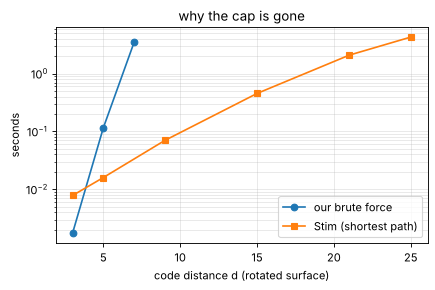

In [3]:
# compare: our brute force grows exponentially, Stim's shortest path does not
bf = []
for d in (3, 5, 7):
    c = surface_rotated(d); t = time.time(); c.distance(max_weight=d + 1); bf.append((d, time.time() - t))
plt.figure(figsize=(6, 3.5))
plt.semilogy([d for d, _ in bf], [t for _, t in bf], "o-", label="our brute force")
plt.semilogy([d for d, _, _ in rows], [max(t, 1e-4) for _, _, t in rows], "s-", label="Stim (shortest path)")
plt.xlabel("code distance d (rotated surface)"); plt.ylabel("seconds"); plt.legend(); plt.grid(alpha=0.3, which="both")
plt.title("why the cap is gone"); plt.show()

### A trap we hit (and fixed)
For codes where one flip lights 3 or more checks, Stim's shortest-path tool first splits those errors into pieces. One piece can end up with **no detectors at all**, and it then looks like a weight-1 logical. On HGP(Hamming, Hamming) that gave d = 1, while the truth is 3. `stim_distance` therefore uses the search for such codes. A test keeps it that way.

In [4]:
hp = hypergraph_product(hamming_H(), hamming_H())
c = code_capacity_circuit(hp, "Z")
print("shortest_graphlike_error (wrong for this code):", len(c.shortest_graphlike_error(ignore_ungraphlike_errors=False)))
print("stim_distance (search):", stim_distance(hp), "   brute force:", hp.distance(max_weight=4))

shortest_graphlike_error (wrong for this code): 1
stim_distance (search): (3, 'upper bound (search)')    brute force: 3


## 2. Logical operators as strings
`code.logicals()` solves the linear algebra and returns *some* valid logical. `reduce_logical` keeps multiplying in stabilizers while the weight drops.
That gives the **same** logical (same commutation with everything) but drawn as a straight line, which is the familiar picture: X̄ across one way, Z̄ across the other.

X-bar weight: linear algebra 5 -> reduced 5 | Z-bar: 5 -> 5


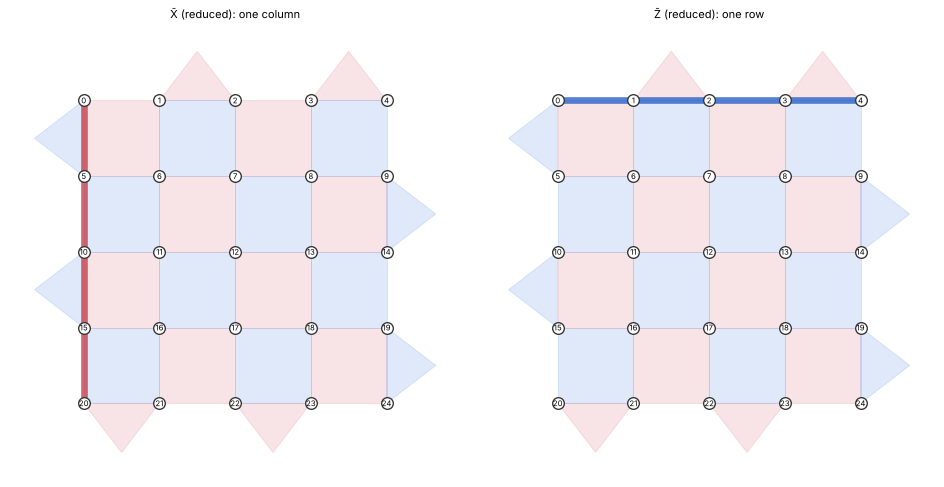

In [5]:
c = surface_rotated(5); n = c.n
LX, LZ = c.logicals(); S = np.hstack([c.Sx, c.Sz])
RX, RZ = reduce_logical(LX[0], S, n), reduce_logical(LZ[0], S, n)
w = lambda v: int((v[:n] | v[n:]).sum())
print("X-bar weight: linear algebra", w(LX[0]), "-> reduced", w(RX), "| Z-bar:", w(LZ[0]), "->", w(RZ))
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
for ax, (L, title) in zip(axs, [(RX, "X̄ (reduced): one column"), (RZ, "Z̄ (reduced): one row")]):
    draw_lattice(c, ax, alpha=0.15, title=title)
    q = np.nonzero(L[:n] | L[n:])[0]; path = logical_path(c, list(q))
    pts = c.geometry.qubit_pos[path["order"]]
    ax.plot(pts[:, 0], pts[:, 1], "-", lw=6, color="#c4424f" if "X" in title else "#2a62c9", alpha=0.8)
plt.tight_layout(); plt.show()

In [6]:
for c in [toric(4), bb("bb72"), bb("gross")]:
    n = c.n; LX, LZ = c.logicals(); S = np.hstack([c.Sx, c.Sz])
    R = reduce_logical(LX[0], S, n); q = list(np.nonzero(R[:n] | R[n:])[0])
    print(f"{c.name:22s} X-bar weight {len(q):3d}, drawn as a {'string' if logical_path(c, q)['string'] else 'set of scattered qubits'}")

toric 4x4              X-bar weight   4, drawn as a string
BB [[72,12,6]]         X-bar weight   6, drawn as a set of scattered qubits


gross [[144,12,12]]    X-bar weight  12, drawn as a set of scattered qubits


## 3. The same code, written three ways
This is exactly what the explorer's *How it’s written* tab shows.

In [7]:
for c in [five_qubit(), bb("gross"), repetition(5)]:
    print("=" * 70, "\n", c.name)
    for sec in written_forms(c):
        if sec["title"] in ("Polynomial form", "Algebraic form"):
            print(sec["text"]); print(sec["pre"])

 five-qubit [[5,1,3]]
A cyclic code over 5 qubits. Write the X part and Z part of the first check as polynomials in x (x = shift by one qubit, x⁵ = 1); the other checks are x, x², x³ times it.
first check XZZXI:
  X part a(x) = 1 + x³
  Z part b(x) = x + x²
check k = ( xᵏ a(x) | xᵏ b(x) )  mod (x⁵ − 1),  k = 0 … 3
(the 5th shift is the product of the other four, so only 4 are independent)
 gross [[144,12,12]]
Each term xᵃyᵇ is one arrow: a check touches the qubit a cells away along x and b cells away along y (which way round is a labelling choice). The same arrows repeat in every cell, which is why one term is one full CNOT layer in the circuit.
torus: l = 12, m = 6   (72 cells, each with an L qubit, an R qubit, an X check, a Z check)
x = cyclic shift by one cell along the l direction  (72 x 72 permutation matrix)
y = cyclic shift by one cell along the m direction

A = x^3 + y + y^2
B = y^3 + x + x^2

H_X = [ A | B ]        (X check at cell c: L qubits c·A, R qubits c·B)
H_Z = [ Bᵀ | A

In [8]:
print("\n".join(written_forms(steane())[0]["pre"].splitlines()))
print()
print(written_forms(steane())[1]["pre"])

S0   (X    )  X0 X1 X3 X4
S1   (X    )  X1 X2 X4 X5
S2   (X    )  X3 X4 X5 X6
S3   (Z    )  Z0 Z1 Z3 Z4
S4   (Z    )  Z1 Z2 Z4 Z5
S5   (Z    )  Z3 Z4 Z5 Z6

H_X  (3 x 7)
1101100
0110110
0001111

H_Z  (3 x 7)
1101100
0110110
0001111
